**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**06 | Subject-Level Cross-Validation for HARTH Classification**

![Subject-level cross-validation workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/06_workflow.svg)

**Objective:** Compare three classical classifiers across participant-disjoint Development folds and examine fold-level and individual-participant variation.

**Dataset:** The eight-participant HARTH v2.0 pilot from Notebook 05, restricted to the published eight-class task.

**Notebook Scope:** Run three GroupKFold splits over six Development participants, with S023 and S032 reserved outside cross-validation. This exploratory analysis is neither nested cross-validation nor an independent final Test evaluation.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ---------------------------- 1. Standard Library ----------------------------
import sys
from pathlib import Path

# --------------------- 2. Repository Path Configuration ----------------------
root = Path.cwd().resolve()
while not (root / "python_modules/core/data_loading.py").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook from inside human-movement-intelligence.")
    root = root.parent
sys.path.insert(0, str(root / "python_modules"))
sys.path.insert(0, str(root / "wearable_activity_recognition/code/src"))

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ----------------------- 5. Shared and Study Utilities -----------------------
from core.output_download import download_outputs_from_colab
from harth_data import ensure_harth_sample, load_harth_subject
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.data_splitting import split_group_indices
from core.group_cross_validation import evaluate_group_cross_validation

# -------------------- 6. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Subject-independent CV utilities ready")
print("Research output directory:", output_dir)

Subject-independent CV utilities ready
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Recreate the Eight-Participant HARTH Source Cohort**

Reuse the participant list, label-pure windows and statistical features from Notebook 05. Source recordings are retrieved from the pinned release or local cache.

In [3]:
# ================ 02. Recreate the Eight-Person Source Cohort ================

# -------------------- 1. Cohort and Source Configuration ---------------------
SUBJECTS = ["S023", "S024", "S025", "S027", "S028", "S032", "S034", "S035"]
TASK_CLASSES = tuple(range(1, 9))
data_dir = root / "data/raw/harth_v2"

feature_parts, meta_parts = [], []

# -------------------- 2. Extract Per-Participant Features --------------------
for subject in SUBJECTS:
    path = ensure_harth_sample(data_dir, subject=subject)
    data, channels = load_harth_subject(path, allow_unmapped_labels=True)  # Retain unknown source labels for the audit.
    windows, y, info = create_signal_windows(
        signals=data[channels].to_numpy(),
        labels=data["label"].to_numpy(),
        window_size=100, step_size=50,
        timestamps=data["timestamp"], sampling_rate=50,
        min_label_purity=1.0, subject_id=subject,  # Require a single activity per window.
    )
    feature_parts.append(extract_signal_features(windows, channel_names=channels))
    meta_parts.append(info)

# --------------------- 3. Combine Features and Metadata ----------------------
features_all = pd.concat(feature_parts, ignore_index=True)
metadata_all = pd.concat(meta_parts, ignore_index=True)
assert len(features_all) == len(metadata_all)

print("All source windows:", len(metadata_all))


Downloaded 12,061,722 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
HARTH subject S023: 137,646 rows, 6 sensors
Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Input windows: (2567, 6, 100)
Feature matrix: (2567, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,

/tmp/ipykernel_3208/832437686.py:13: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)  # Retain unknown source labels for the audit.


HARTH subject S032: 178,341 rows, 6 sensors
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Input windows: (3038, 6, 100)
Feature matrix: (3038, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Input windows: (3337, 6, 100)
Feature matr

**03. Restrict the Eight-Class Task and Reserve Test Participants**

Apply the eight-class filter after windowing, then reproduce the fixed-seed participant split. S023 and S032 remain excluded from Development cross-validation. Their later qualified held-out evaluation follows a separate protocol.

In [4]:
# ================ 03. Restrict Task and Reserve Original Test ================

# --------------------- 1. Audit Labels and Restrict Task ---------------------
eligible = metadata_all["label"].isin(TASK_CLASSES).to_numpy()
excluded = metadata_all.loc[~eligible, "label"].value_counts().sort_index()
features = features_all.loc[eligible].reset_index(drop=True)
metadata = metadata_all.loc[eligible].reset_index(drop=True)
print("Excluded source-code windows:", excluded.to_dict())

# ------------------- 2. Create Participant-Disjoint Split --------------------
partitions = split_group_indices(
    group_ids=metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)
development_indices = np.sort(np.concatenate([
    partitions["train"], partitions["validation"]
]))

reserved_test_indices = partitions["test"]  # Keep original Test participants outside Development CV.

# ------------------- 3. Development Data and Test Boundary -------------------
development_features = features.iloc[development_indices].to_numpy()
development_labels = metadata.iloc[development_indices]["label"].to_numpy()
development_subjects = metadata.iloc[development_indices]["subject_id"].to_numpy()
reserved_subjects = set(metadata.iloc[reserved_test_indices]["subject_id"])

assert not (set(development_subjects) & reserved_subjects)

# ----------------------------- 4. Cohort Summary -----------------------------
print("Development participants:", sorted(set(development_subjects)))
print("Reserved final Test participants:", sorted(reserved_subjects))

print("Development matrix:", development_features.shape)


Excluded source-code windows: {10: 1, 13: 1018, 14: 238, 130: 78, 140: 65}
Independent groups: 8
train: 4 groups | 12,489 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,604 rows
Development participants: ['S024', 'S025', 'S027', 'S028', 'S034', 'S035']
Reserved final Test participants: ['S023', 'S032']
Development matrix: (18959, 30)


**04. Run Three Participant-Disjoint Development Folds**

Each GroupKFold split holds out two Development participants. Refit all classifiers for each fold, including the Logistic Regression scaler on fold Train data only. Check training-class coverage before fitting. Balanced accuracy averages recall over classes present in each Validation fold; scikit-learn may warn when the model predicts a class absent from that fold's reference labels. Fixed-task Macro F1 instead includes all eight predefined classes.

In [5]:
# ================ 04. Run Three Participant-Disjoint CV Folds ================
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=development_features,
    labels=development_labels,
    group_ids=development_subjects,
    classes=TASK_CLASSES,
    n_splits=3,
    random_state=42,
)
display(summary.round(4))

display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "validation_classes_present", "macro_f1", "balanced_accuracy",
]].round(4))


Fold 1: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0551
Logistic Regression: Validation Macro F1 = 0.7882
Random Forest: Validation Macro F1 = 0.6853
Fold 2: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0565


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Logistic Regression: Validation Macro F1 = 0.6387
Random Forest: Validation Macro F1 = 0.7030
Fold 3: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.1031
Logistic Regression: Validation Macro F1 = 0.8036
Random Forest: Validation Macro F1 = 0.7516


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Logistic Regression,0.7435,0.0910,0.6387,0.8036,0.6751,0.7910
1,Random Forest,0.7133,0.0343,0.6853,0.7516,0.6463,0.7701
2,Dummy (most frequent),0.0715,0.0273,0.0551,0.1031,0.0668,0.0795


,fold,model,train_subjects,validation_subjects,validation_classes_present,macro_f1,balanced_accuracy
0,1,Logistic Regression,"S024, S027, S028, S035","S025, S034",8,0.7882,0.8441
1,1,Random Forest,"S024, S027, S028, S035","S025, S034",8,0.6853,0.6788
2,1,Dummy (most frequent),"S024, S027, S028, S035","S025, S034",8,0.0551,0.1250
3,2,Random Forest,"S024, S025, S028, S034","S027, S035",6,0.7030,0.9628
4,2,Logistic Regression,"S024, S025, S028, S034","S027, S035",6,0.6387,0.9573
5,2,Dummy (most frequent),"S024, S025, S028, S034","S027, S035",6,0.0565,0.1667
6,3,Logistic Regression,"S025, S027, S034, S035","S024, S028",8,0.8036,0.9078
7,3,Random Forest,"S025, S027, S034, S035","S024, S028",8,0.7516,0.7405
8,3,Dummy (most frequent),"S025, S027, S034, S035","S024, S028",8,0.1031,0.1250


**05. Visualise Fold-to-Fold Macro F1 Variation**

Plot individual fold scores and their mean. With only two held-out participants per fold, the observed variation should not be treated as a precise uncertainty estimate.

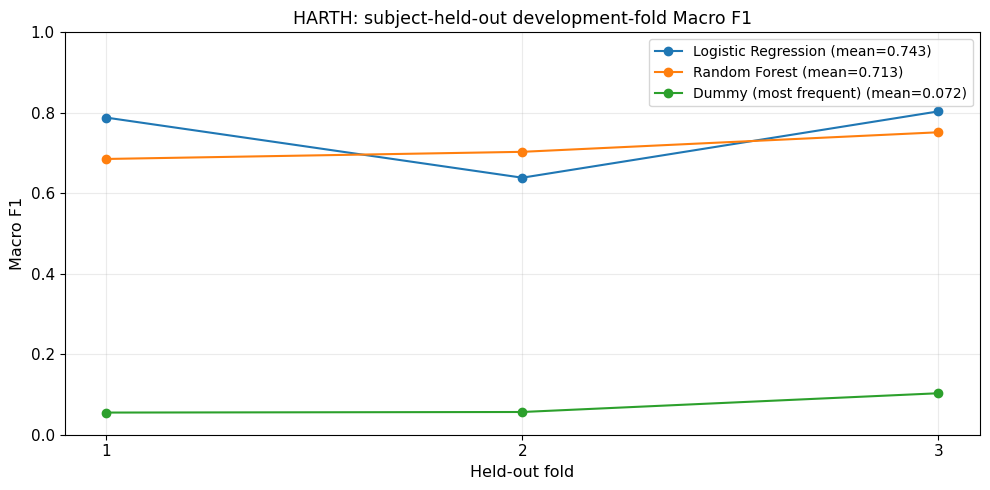

In [6]:
# ================= 05. Visualise Fold-Level Score Variation ==================
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(
        table["fold"], table["macro_f1"], marker="o",
        label=f"{model_name} (mean={table['macro_f1'].mean():.3f})",
    )

ax.set(
    title="HARTH: subject-held-out development-fold Macro F1",
    xlabel="Held-out fold", ylabel="Macro F1",
    xticks=[1, 2, 3], ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "06_cross_validation_fold_macro_f1.png")
plt.show()


**06. Examine Participant-Level Classification Variation**

Compare fixed eight-class Macro F1 with Macro F1 calculated over classes present in each participant's labels. The denominators differ and must be stated when interpreting individual scores.

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task,macro_f1_observed_classes
12,3,Dummy (most frequent),S024,3119,8,0.0809,0.0809
0,1,Dummy (most frequent),S025,2873,8,0.0754,0.0754
6,2,Dummy (most frequent),S027,3082,6,0.0028,0.0037
13,3,Dummy (most frequent),S028,3197,7,0.1197,0.1369
1,1,Dummy (most frequent),S034,3351,7,0.0334,0.0382
7,2,Dummy (most frequent),S035,3337,5,0.0888,0.1421
14,3,Logistic Regression,S024,3119,8,0.7825,0.7825
2,1,Logistic Regression,S025,2873,8,0.7896,0.7896
8,2,Logistic Regression,S027,3082,6,0.5705,0.7607
15,3,Logistic Regression,S028,3197,7,0.7485,0.8555


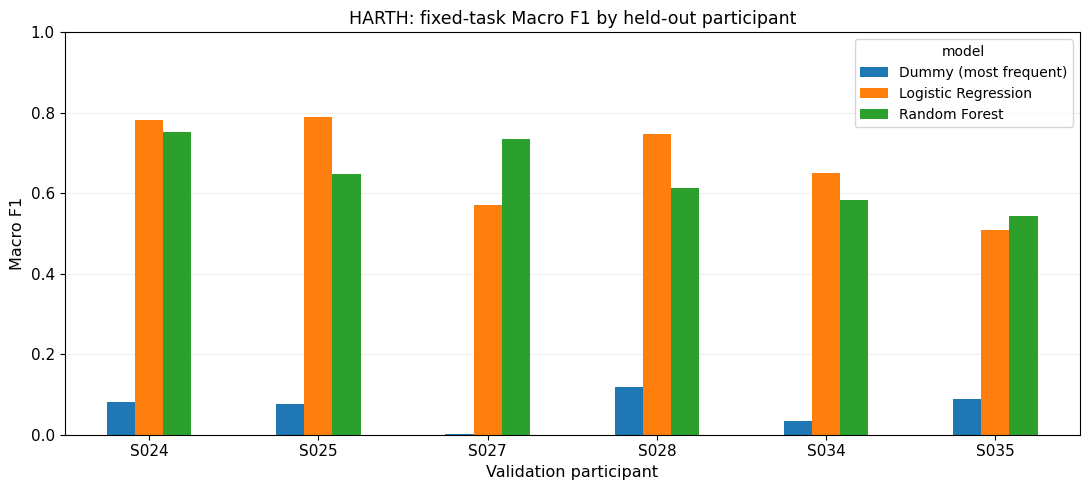

In [7]:
# ================== 06. Inspect Participant-Level Variation ==================

# ----------------------- 1. Participant-Level Results ------------------------
display(subject_results.sort_values(["model", "subject_id"]).round(4))

# ---------------------- 2. Visualise Fixed-Task Scores -----------------------
plot_data = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).sort_index()
ax = plot_data.plot(kind="bar", figsize=(11, 5), rot=0)
ax.set(
    title="HARTH: fixed-task Macro F1 by held-out participant",
    xlabel="Validation participant", ylabel="Macro F1", ylim=(0, 1),
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
save_figure(ax.figure, output_dir / "06_cross_validation_participant_macro_f1.png")
plt.show()


**07. Development-Only Cross-Validation Quality Gate**

Verify participant separation, class definitions and fold coverage without accessing reserved Test data. These six-person Development results are exploratory and do not establish performance on an independent cohort.


In [8]:
# =============== 07. Development Cross-Validation Quality Gate ===============

# ----------------- 1. Verify Groups and Evaluation Integrity -----------------
assert len(set(development_subjects)) == 6
assert set(subject_results["subject_id"]) == set(development_subjects)
assert not (set(subject_results["subject_id"]) & reserved_subjects)
assert subject_results.groupby(["model", "subject_id"]).size().eq(1).all()
assert fold_results["macro_f1"].between(0, 1).all()
assert len(fold_results) == 3 * 3

# ------------------------- 2. Quality Gate and Scope -------------------------
print("Development-only group CV: PASSED")
print("Reserved final Test inference: NOT PERFORMED")
print("Formal full-dataset generalisation claim: NOT SUPPORTED")

# ------------------------ 3. Save Development CV Evidence --------------------
summary.to_csv(output_dir / "06_development_cv_model_summary.csv", index=False)
fold_results.to_csv(output_dir / "06_development_cv_fold_metrics.csv", index=False)
subject_results.to_csv(output_dir / "06_development_cv_participant_metrics.csv", index=False)
partition_membership = pd.DataFrame([
    {
        "partition": name,
        "subject_id": subject,
        "role": "reserved exploratory Test" if name == "test" else "Development",
    }
    for name, indices in partitions.items()
    for subject in sorted(set(metadata.iloc[indices]["subject_id"]))
])
partition_membership.to_csv(output_dir / "06_exploratory_participant_split.csv", index=False)
print("Saved Development-only cross-validation evidence in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="06")

Development-only group CV: PASSED
Reserved final Test inference: NOT PERFORMED
Formal full-dataset generalisation claim: NOT SUPPORTED
Saved Development-only cross-validation evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output
------------------------------------------------------------------------
Notebook stage: 06
Files packaged: 6
  + 06_cross_validation_fold_macro_f1.png
  + 06_cross_validation_participant_macro_f1.png
  + 06_development_cv_fold_metrics.csv
  + 06_development_cv_model_summary.csv
  + 06_development_cv_participant_metrics.csv
  + 06_exploratory_participant_split.csv
Download ZIP from Colab Contents: /content/wearable_activity_recognition_Stage_06_Outputs.zip
GitHub Commit/Push performed: NO
